--------
## Vishal kumar
## PRN - 260840128053
------

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression

# Load Data 

In [2]:
inpDir = Path('..') / '..'/'input'
outDir = Path('..') /'output'
RANDOM_STATE = 24
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE)

NOISE = 0.2
EPOCHS = 200
ALPHA = 0.1
N_SAMPLES = 1000

# parameters for matplotlib
params = {'legend.fontsize': 'medium',
          'figure.figsize': (15, 12),
          'axes.labelsize': 'medium',
          'axes.titlesize':'medium',
          'xtick.labelsize':'medium',
          'ytick.labelsize':'medium',
          'savefig.dpi': 150,
          'image.cmap': plt.cm.coolwarm,
          'image.interpolation': 'none',
          'savefig.bbox' : 'tight',
          'lines.linewidth' : 2,
          'legend.numpoints' : 1
         }


In [3]:
data_df = pd.read_csv('breast_cancer_mod.csv')
data_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,0,0,0,0,0,0,0,0,0,1,...,0,0,0,1,1,0,0,1,1,0
1,0,1,0,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
2,0,1,0,0,0,0,0,0,0,1,...,1,0,1,0,1,1,0,1,1,0
3,0,1,0,0,0,0,0,0,0,1,...,1,0,0,0,0,0,0,1,1,0
4,0,0,0,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,1,0


In [4]:
data_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   mean radius              569 non-null    int64
 1   mean texture             569 non-null    int64
 2   mean perimeter           569 non-null    int64
 3   mean area                569 non-null    int64
 4   mean smoothness          569 non-null    int64
 5   mean compactness         569 non-null    int64
 6   mean concavity           569 non-null    int64
 7   mean concave points      569 non-null    int64
 8   mean symmetry            569 non-null    int64
 9   mean fractal dimension   569 non-null    int64
 10  radius error             569 non-null    int64
 11  texture error            569 non-null    int64
 12  perimeter error          569 non-null    int64
 13  area error               569 non-null    int64
 14  smoothness error         569 non-null    int64
 15  compac

In [5]:
data_df.isna().sum().sum()

0

In [6]:
data_df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

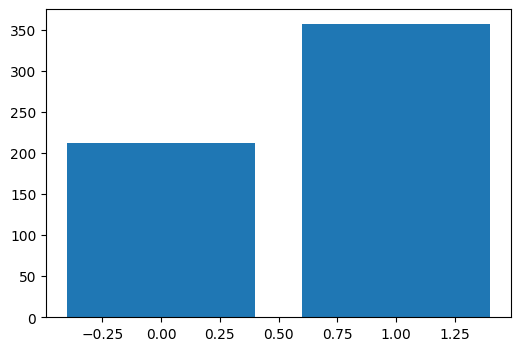

In [7]:
class_names = ['Malignant','Benign']
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(data_df['target'].value_counts().index,data_df['target'].value_counts().values);

In [8]:
features = data_df.drop('target',axis = 1)
labels = data_df['target']

X_train,X_test,y_train,y_test = train_test_split(features,labels,test_size=0.25,stratify = labels,random_state=RANDOM_STATE)

In [9]:
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(426, 30) (143, 30) (426,) (143,)


# Training 

In [10]:
X_train['total'] = X_train.astype(np.int16).sum(axis = 1)
X_train['target'] = y_train
X_train= X_train.sort_values('total')

X_train.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,total,target
0,0,0,0,0,0,0,0,0,0,1,...,0,0,1,1,0,0,1,1,12,0
2,0,1,0,0,0,0,0,0,0,1,...,0,1,0,1,1,0,1,1,13,0
1,0,1,0,1,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,13,0
5,0,0,0,0,0,0,0,0,0,1,...,0,1,0,1,0,0,1,1,15,0
6,0,0,0,0,1,0,0,0,1,1,...,0,0,0,0,0,0,1,1,15,0


In [11]:
X_train['target']

0      0
2      0
1      0
5      0
6      0
      ..
356    1
503    1
484    1
454    1
383    1
Name: target, Length: 426, dtype: int64

In [12]:
accuracy = {}
for b in range(X_train.shape[1]):
    X_train['y_pred']= X_train['total']>=b
    accuracy[b] = accuracy_score(X_train['target'],X_train['y_pred'])

In [13]:
accuracy

{0: 0.6267605633802817,
 1: 0.6267605633802817,
 2: 0.6267605633802817,
 3: 0.6267605633802817,
 4: 0.6267605633802817,
 5: 0.6267605633802817,
 6: 0.6267605633802817,
 7: 0.6267605633802817,
 8: 0.6267605633802817,
 9: 0.6267605633802817,
 10: 0.6267605633802817,
 11: 0.6267605633802817,
 12: 0.6267605633802817,
 13: 0.6291079812206573,
 14: 0.6338028169014085,
 15: 0.6338028169014085,
 16: 0.6408450704225352,
 17: 0.647887323943662,
 18: 0.6572769953051644,
 19: 0.6619718309859155,
 20: 0.6713615023474179,
 21: 0.6901408450704225,
 22: 0.7089201877934272,
 23: 0.7323943661971831,
 24: 0.7699530516431925,
 25: 0.8051643192488263,
 26: 0.8286384976525821,
 27: 0.8474178403755869,
 28: 0.8450704225352113,
 29: 0.8192488262910798,
 30: 0.7394366197183099,
 31: 0.3732394366197183}

In [14]:
best_b = max(accuracy,key = accuracy.get)

In [15]:
best_b

27

In [16]:
best_b = max(accuracy,key = accuracy.get)
print('Optimal value of b is', best_b)
print('Highest accuracy is: {0:4.2f} %'.format(accuracy[best_b] *100))

Optimal value of b is 27
Highest accuracy is: 84.74 %
